# Neural audio codecs up close: codebooks and residual vector quantization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dorienh/music-ai-explained/blob/main/02-neural-audio-codecs/notebook.ipynb)

Companion to the article *Neural Audio Codecs Up Close*. We build vector quantization and RVQ from nothing, train a VQ layer, then open up two real codecs.

Runs on a CPU. The last section (codebook usage of EnCodec and DAC) takes a few minutes.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q librosa soundfile encodec descript-audio-codec

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, librosa, matplotlib.pyplot as plt
from IPython.display import Audio, display

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "lines.linewidth": 2, "figure.dpi": 110})

def clip(name, sr=None, offset=0.0, duration=None):
    """Load one of librosa's freely licensed example recordings (downloaded on first use)."""
    y, sr = librosa.load(librosa.example(name, hq=True), sr=sr, mono=True, offset=offset, duration=duration)
    return y, sr
import torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(0); rng = np.random.default_rng(0)

## 1. A codebook, by hand

Four entries in two dimensions. Quantizing a frame means finding the nearest entry and storing its row number.

In [3]:
codebook = np.array([[1.0, 1.0], [1.0, 3.0], [3.0, 1.0], [3.0, 3.0]])
frame = np.array([1.4, 2.6])

squared_distances = ((codebook - frame) ** 2).sum(axis=1)
index = squared_distances.argmin()
print("squared distance to each entry:", squared_distances)
print("stored index:", index, f"({np.log2(len(codebook)):.0f} bits)")
print("decoder looks up:", codebook[index], " error:", frame - codebook[index])

squared distance to each entry: [2.72 0.32 5.12 2.72]
stored index: 1 (2 bits)
decoder looks up: [1. 3.]  error: [ 0.4 -0.4]


## 2. Learning a codebook from music

Frames here are 64-number summaries of short slices of music (log-mel spectrogram frames). We learn codebooks with k-means on five pieces and test on a sixth the codebooks never saw. Score: relative error (0 is perfect, 1 is as bad as outputting silence).

In [4]:
def mel_frames(name, duration=60):
    y, sr = clip(name, sr=22050, duration=duration)
    M = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024, hop_length=512, n_mels=64)
    return np.log(M + 1e-5).T                                   # [frames, 64]

train = np.concatenate([mel_frames(n) for n in ("nutcracker", "brahms", "vibeace", "sweetwaltz", "fishin")])
test = mel_frames("pistachio")
mean = train.mean(axis=0); train -= mean; test -= mean
print("training frames:", train.shape, " unseen test frames:", test.shape)

def nearest(X, C):                                              # index of the nearest entry for each frame
    return ((X ** 2).sum(1)[:, None] - 2 * X @ C.T + (C ** 2).sum(1)[None]).argmin(axis=1)

def kmeans(X, K, iterations=20):
    C = X[rng.choice(len(X), K, replace=False)].copy()          # start from random frames
    for _ in range(iterations):
        idx = nearest(X, C)                                     # assign
        for k in range(K):
            if (idx == k).any(): C[k] = X[idx == k].mean(axis=0)  # update
    return C

relative_error = lambda X, Xq: ((X - Xq) ** 2).sum() / (X ** 2).sum()

single = {}
for K in (16, 256, 1024):
    C = kmeans(train, K)
    single[int(np.log2(K))] = relative_error(test, C[nearest(test, C)])
    print(f"one codebook, {K:5d} entries ({np.log2(K):2.0f} bits): train {relative_error(train, C[nearest(train, C)]):.3f}   unseen {single[int(np.log2(K))]:.3f}")

training frames: (11846, 64)  unseen test frames: (2584, 64)
one codebook,    16 entries ( 4 bits): train 0.287   unseen 0.592
one codebook,   256 entries ( 8 bits): train 0.126   unseen 0.504


one codebook,  1024 entries (10 bits): train 0.071   unseen 0.469


## 3. Residual vector quantization

Quantize in stages. Each stage has its own small codebook and describes only what the previous stages left over.

In [5]:
def rvq_encode(frame, codebooks):
    residual, indices = frame.copy(), []
    for C in codebooks:
        i = ((C - residual) ** 2).sum(axis=1).argmin()          # nearest entry
        indices.append(int(i))
        residual = residual - C[i]                              # what is still unexplained
    return indices

def rvq_decode(indices, codebooks):
    return sum(C[i] for C, i in zip(codebooks, indices))

# the worked example from the article: the "frame" is the single number 7.26
toy = [np.array([[0.], [4.], [8.], [12.]]), np.array([[-1.5], [-0.5], [0.5], [1.5]]), np.array([[-0.3], [-0.1], [0.1], [0.3]])]
codes = rvq_encode(np.array([7.26]), toy)
print("stored indices:", codes, " decoded:", rvq_decode(codes, toy), " error:", 7.26 - rvq_decode(codes, toy)[0])

stored indices: [2, 1, 0]  decoded: [7.2]  error: 0.05999999999999961


Now on the music frames: stages of only 16 entries each, each trained on the residual of the previous ones.

1 stages ( 4 bits,  16 stored vectors): train 0.295   unseen 0.610
2 stages ( 8 bits,  32 stored vectors): train 0.214   unseen 0.497
3 stages (12 bits,  48 stored vectors): train 0.175   unseen 0.423
4 stages (16 bits,  64 stored vectors): train 0.148   unseen 0.374
5 stages (20 bits,  80 stored vectors): train 0.129   unseen 0.337
6 stages (24 bits,  96 stored vectors): train 0.113   unseen 0.303


7 stages (28 bits, 112 stored vectors): train 0.100   unseen 0.276
8 stages (32 bits, 128 stored vectors): train 0.090   unseen 0.253


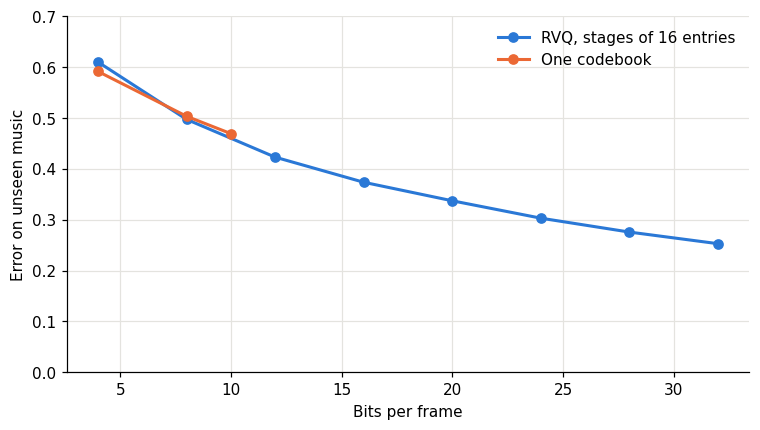

In [6]:
residual, q_train, q_test, rvq = train.copy(), np.zeros_like(train), np.zeros_like(test), {}
for stage in range(1, 9):
    C = kmeans(residual, 16)
    q_train += C[nearest(train - q_train, C)]; residual = train - q_train
    q_test += C[nearest(test - q_test, C)]
    rvq[4 * stage] = relative_error(test, q_test)
    print(f"{stage} stages ({4 * stage:2d} bits, {16 * stage:3d} stored vectors): train {relative_error(train, q_train):.3f}   unseen {rvq[4 * stage]:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(list(rvq), list(rvq.values()), "-o", color=BLUE, label="RVQ, stages of 16 entries")
ax.plot(list(single), list(single.values()), "-o", color=ORANGE, label="One codebook")
ax.set_ylim(0, 0.7); ax.set_xlabel("Bits per frame"); ax.set_ylabel("Error on unseen music"); ax.legend(frameon=False); plt.show()

## 4. A trainable VQ layer

Inside a neural codec the codebook is learned together with the encoder. Three ingredients: a codebook loss (pull entries towards the frames that chose them), a commitment loss (pull frames towards their entries) and the straight-through estimator (let gradients skip the non-differentiable lookup).

In [7]:
class VQ(nn.Module):
    def __init__(self, K, D, beta=0.25):
        super().__init__()
        self.codebook = nn.Embedding(K, D)            # the table: K entries of D numbers
        self.beta = beta

    def forward(self, z):                             # z: [N, D], N frames
        dist = torch.cdist(z, self.codebook.weight)   # distance to every entry
        idx = dist.argmin(-1)                         # nearest entry per frame
        q = self.codebook(idx)                        # look it up
        loss = F.mse_loss(q, z.detach()) + self.beta * F.mse_loss(z, q.detach())
        q = z + (q - z).detach()                      # straight-through estimator
        return q, idx, loss

corners = torch.tensor([[1., 1.], [1., 3.], [3., 1.], [3., 3.]])
data = torch.randn(4096, 2) * 0.3 + corners.repeat(1024, 1)     # points scattered around four corners
encoder, decoder, vq = nn.Linear(2, 2), nn.Linear(2, 2), VQ(4, 2)
opt = torch.optim.Adam([*encoder.parameters(), *decoder.parameters(), *vq.parameters()], lr=1e-2)
for step in range(2001):
    q, idx, vq_loss = vq(encoder(data)); out = decoder(q)
    loss = F.mse_loss(out, data) + vq_loss
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 500 == 0:
        print(f"step {step:4d}: reconstruction error {F.mse_loss(out, data).item():.4f}, entries in use {idx.unique().numel()}/4")

step    0: reconstruction error 7.2462, entries in use 2/4


step  500: reconstruction error 0.3314, entries in use 4/4


step 1000: reconstruction error 0.0901, entries in use 4/4


step 1500: reconstruction error 0.0899, entries in use 4/4


step 2000: reconstruction error 0.0899, entries in use 4/4


## 5. A real codec: EnCodec

24 kHz audio, 75 frames per second, up to 32 codebooks of 1,024 entries. Bitrate = frames per second × codebooks × 10 bits.

In [8]:
from encodec import EncodecModel
enc = EncodecModel.encodec_model_24khz().eval()
enc.set_target_bandwidth(24.0)                                   # use all 32 codebooks

y, _ = clip("fishin", sr=24000, offset=30, duration=10)
x = torch.from_numpy(y)[None, None]                              # [batch, channels, samples]
with torch.no_grad():
    codes = torch.cat([c for c, _ in enc.encode(x)], dim=-1)
print("codes:", tuple(codes.shape), "= (batch, codebooks, frames)")
print("first frame, first 8 codebooks:", codes[0, :8, 0].tolist())
print(f"bitrate with 8 codebooks: {codes.shape[-1] / 10:.0f} frames/s x 8 x 10 bits = {codes.shape[-1] / 10 * 8 * 10 / 1000:.1f} kbit/s")

codes: (1, 32, 751) = (batch, codebooks, frames)
first frame, first 8 codebooks: [822, 814, 536, 603, 8, 521, 442, 65]
bitrate with 8 codebooks: 75 frames/s x 8 x 10 bits = 6.0 kbit/s


Coarse first, detail later: decode the same clip with 1, 2, 8 and 32 codebooks.

In [9]:
print("original"); display(Audio(y, rate=24000))
for k in (1, 2, 8, 32):
    with torch.no_grad():
        out = enc.decode([(codes[:, :k], None)])[0, 0].numpy()
    print(f"{k} codebook(s), {0.75 * k:.2f} kbit/s"); display(Audio(out, rate=24000))

original


[audio player: run the cell to listen]


1 codebook(s), 0.75 kbit/s


[audio player: run the cell to listen]


2 codebook(s), 1.50 kbit/s


[audio player: run the cell to listen]


8 codebook(s), 6.00 kbit/s


[audio player: run the cell to listen]


32 codebook(s), 24.00 kbit/s


[audio player: run the cell to listen]


## 6. Are the codebooks used well?

Entropy measures how much information an index really carries. The maximum for 1,024 entries is 10 bits. We measure it on seven minutes of music for EnCodec and DAC. Set `RUN_DAC = False` to skip DAC, which is slower.

In [10]:
def entropy_bits(indices, K=1024):
    p = np.bincount(indices, minlength=K) / len(indices)
    used = (p > 0).sum(); p = p[p > 0]
    return -(p * np.log2(p)).sum(), used

for name, p in (("8 entries used equally", np.ones(8) / 8), ("8 entries, skewed", np.array([.5, .25, .125, .0625, .03125, .03125]))):
    H = -(p * np.log2(p)).sum(); print(f"{name}: entropy {H:.2f} bits, perplexity {2 ** H:.1f}")

8 entries used equally: entropy 3.00 bits, perplexity 8.0
8 entries, skewed: entropy 1.94 bits, perplexity 3.8


EnCodec | frames: 27024
  codebook 1: 8.56 bits, 775 of 1024 entries used
  codebook 2: 9.05 bits, 956 of 1024 entries used
  codebook 3: 9.17 bits, 942 of 1024 entries used
  codebook 4: 9.30 bits, 976 of 1024 entries used
  codebook 5: 9.35 bits, 984 of 1024 entries used
  codebook 6: 9.37 bits, 990 of 1024 entries used
  codebook 7: 9.36 bits, 963 of 1024 entries used
  codebook 8: 9.34 bits, 919 of 1024 entries used
  codebook 9: 9.39 bits, 930 of 1024 entries used
  information actually carried by the first 8 codebooks: 73.5 bits per frame
DAC | frames: 31021
  codebook 1: 8.66 bits, 971 of 1024 entries used
  codebook 2: 9.83 bits, 1024 of 1024 entries used
  codebook 3: 9.91 bits, 1024 of 1024 entries used
  codebook 4: 9.89 bits, 1024 of 1024 entries used
  codebook 5: 9.93 bits, 1024 of 1024 entries used
  codebook 6: 9.93 bits, 1024 of 1024 entries used
  codebook 7: 9.93 bits, 1024 of 1024 entries used
  codebook 8: 9.92 bits, 1024 of 1024 entries used
  codebook 9: 9.94 bit

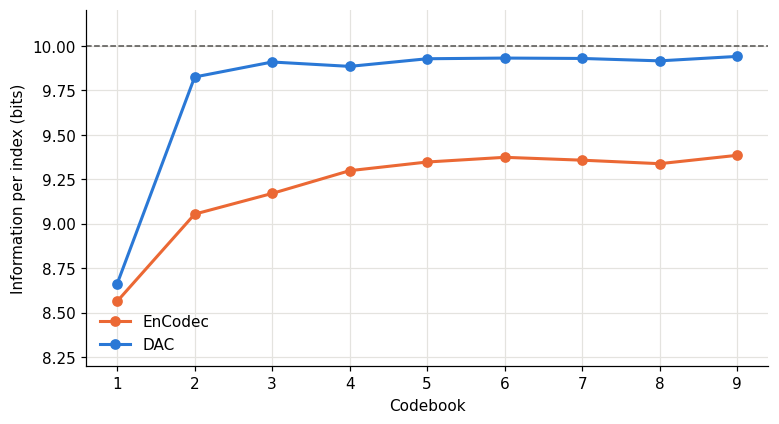

In [11]:
RUN_DAC = True
if RUN_DAC:
    import dac
    dac_model = dac.DAC.load(dac.utils.download(model_type="44khz")).eval()

enc_codes, dac_codes = [], []
for name in ("nutcracker", "brahms", "vibeace", "sweetwaltz", "fishin", "pistachio", "choice"):
    y, sr = clip(name, duration=60)
    for start in range(0, len(y) - sr * 5, sr * 20):             # 20-second chunks
        seg = y[start:start + sr * 20]
        with torch.no_grad():
            x24 = torch.from_numpy(librosa.resample(seg, orig_sr=sr, target_sr=24000))[None, None]
            enc_codes.append(torch.cat([c for c, _ in enc.encode(x24)], -1)[0])
            if RUN_DAC:
                x44 = dac_model.preprocess(torch.from_numpy(seg)[None, None], 44100)
                dac_codes.append(dac_model.encode(x44)[1][0])

results = {"EnCodec": torch.cat(enc_codes, -1).numpy()}
if RUN_DAC: results["DAC"] = torch.cat(dac_codes, -1).numpy()
fig, ax = plt.subplots(figsize=(8, 4.2))
for (name, C), color in zip(results.items(), (ORANGE, BLUE)):
    H = [entropy_bits(C[i]) for i in range(9)]
    print(name, "| frames:", C.shape[1])
    for i, (h, used) in enumerate(H): print(f"  codebook {i + 1}: {h:.2f} bits, {used} of 1024 entries used")
    print(f"  information actually carried by the first {8 if name == 'EnCodec' else 9} codebooks: {sum(h for h, _ in H[:8 if name == 'EnCodec' else 9]):.1f} bits per frame")
    ax.plot(range(1, 10), [h for h, _ in H], "-o", color=color, label=name)
ax.axhline(10, color=INK2, lw=1, ls="--"); ax.set_ylim(8.2, 10.2)
ax.set_xlabel("Codebook"); ax.set_ylabel("Information per index (bits)"); ax.legend(frameon=False); plt.show()

## Where next

- The articles: [Music & AI on Medium](https://medium.com/@dorien-herremans/list/music-ai-3fb88d4826dd)
- The next notebook: [running and comparing codecs](../03-comparing-codecs/notebook.ipynb)
- For the full picture: [A Tutorial on Generative Models for Music Audio](https://arxiv.org/abs/2610.38252)